EXPERIMENT 9 — ASK AND BFSK DIGITAL COMMUNICATION

THEORY:
----------------------------------------------------------------------

ASK:
Binary ASK uses the amplitude of a carrier to represent bits.
Here:
    bit 1 -> carrier transmitted
    bit 0 -> carrier absent

Coherent ASK detection correlates the received signal with a
phase-synchronized carrier.

Noncoherent ASK detection estimates the received signal energy
without requiring carrier phase synchronization.

BFSK:
Binary FSK uses two different carrier frequencies:
    bit 0 -> f1
    bit 1 -> f2

Coherent BFSK detection correlates the received signal with
both known carriers.

Noncoherent BFSK detection measures the energy associated with
each frequency using I/Q correlations.


BFSK ORTHOGONALITY CONDITION
----------------------------------------------------------------------

For coherent binary FSK, the two basis signals should be
orthogonal over one bit interval.

For tones:

    cos(2πf1t)
    cos(2πf2t)

the inner product s

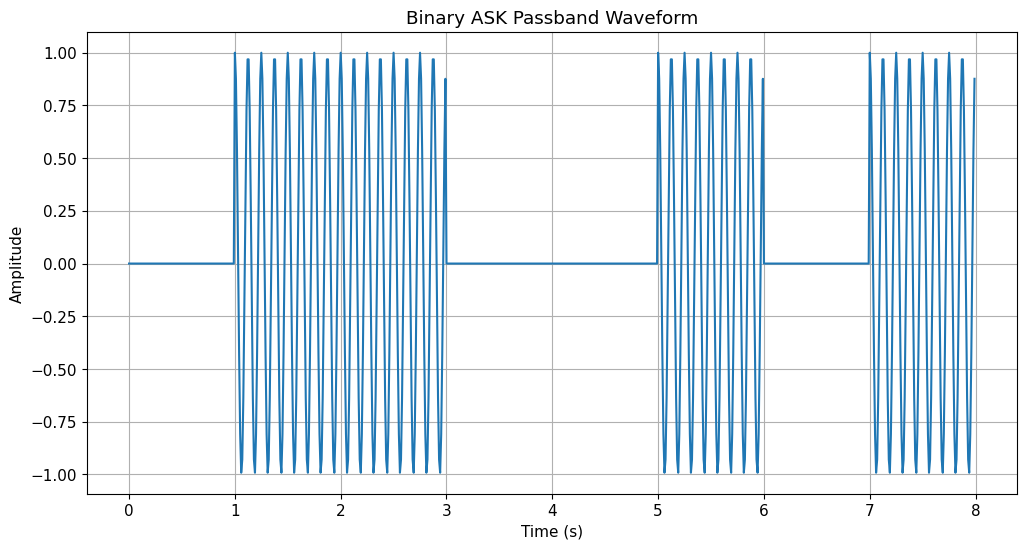

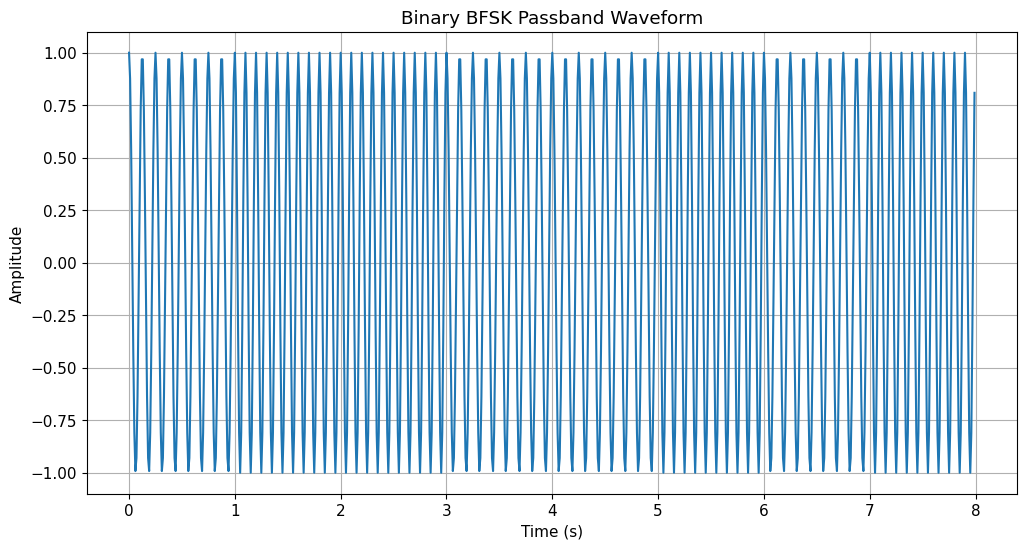

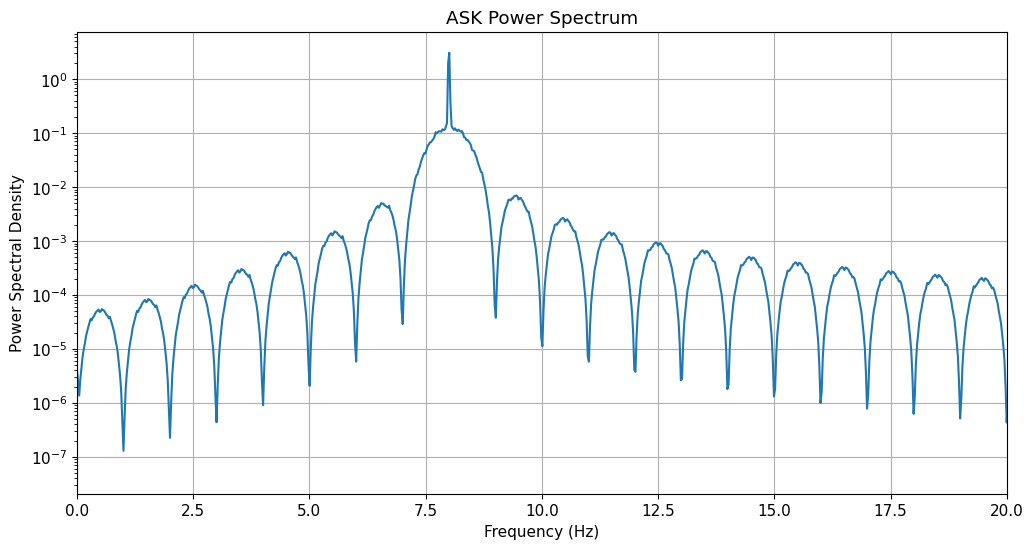

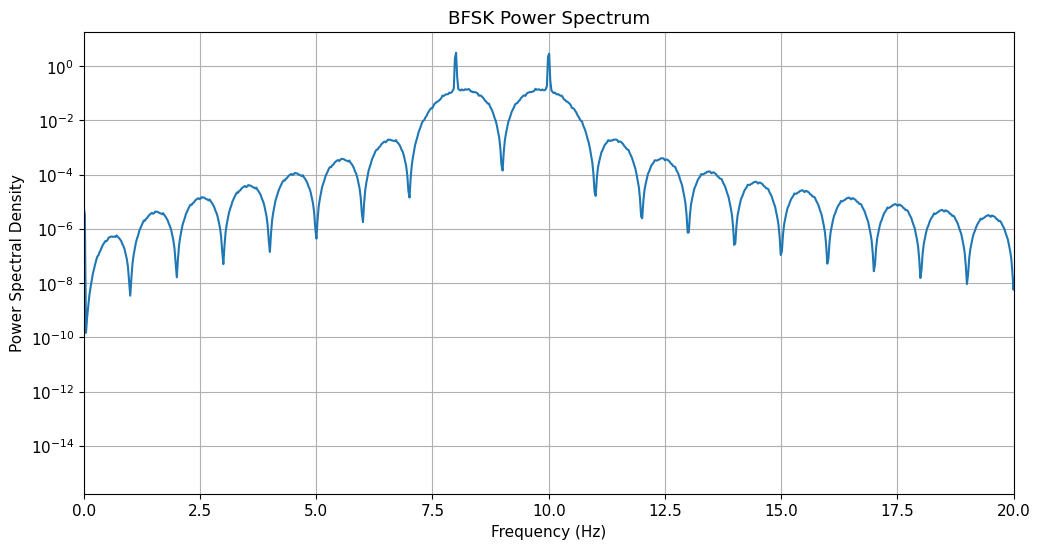


Channel:
AWGN SNR = 6 dB

ASK COHERENT DETECTION
----------------------------------------------------------------------
Threshold = 1.76259
BER = 0.000000

ASK NONCOHERENT ENERGY DETECTION
----------------------------------------------------------------------
Threshold = 0.36186
BER = 0.000000

BFSK COHERENT DETECTION
----------------------------------------------------------------------
BER = 0.000000

BFSK NONCOHERENT DETECTION
----------------------------------------------------------------------
BER = 0.000000


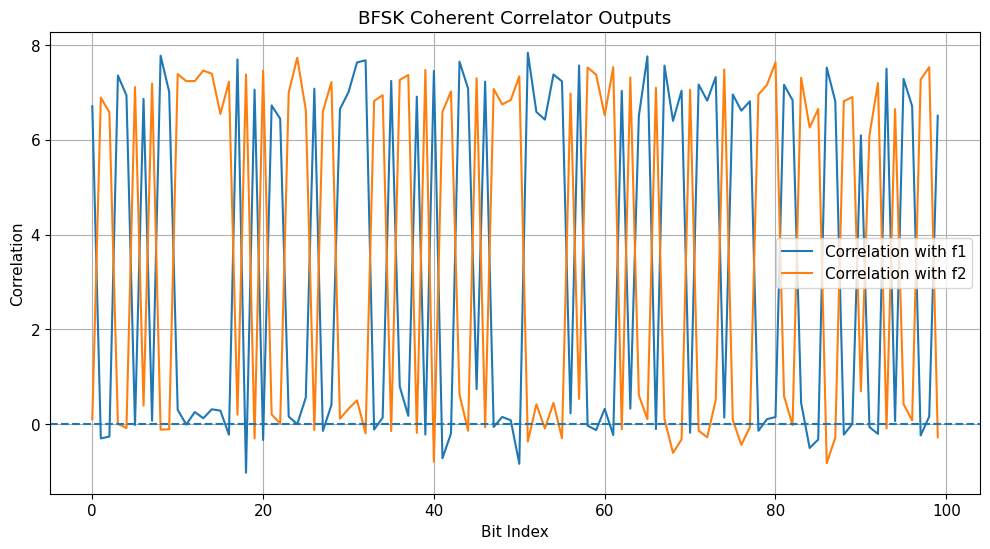

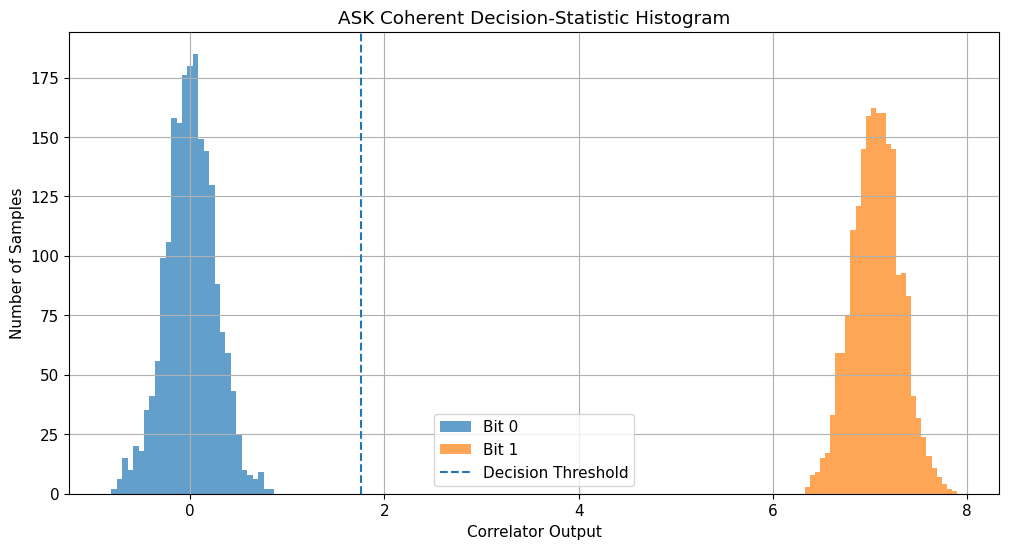

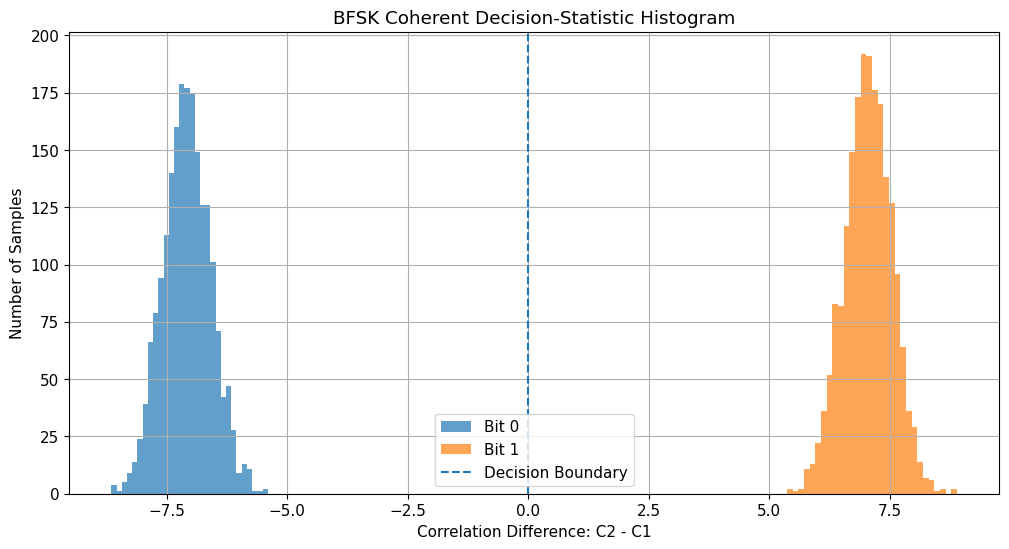

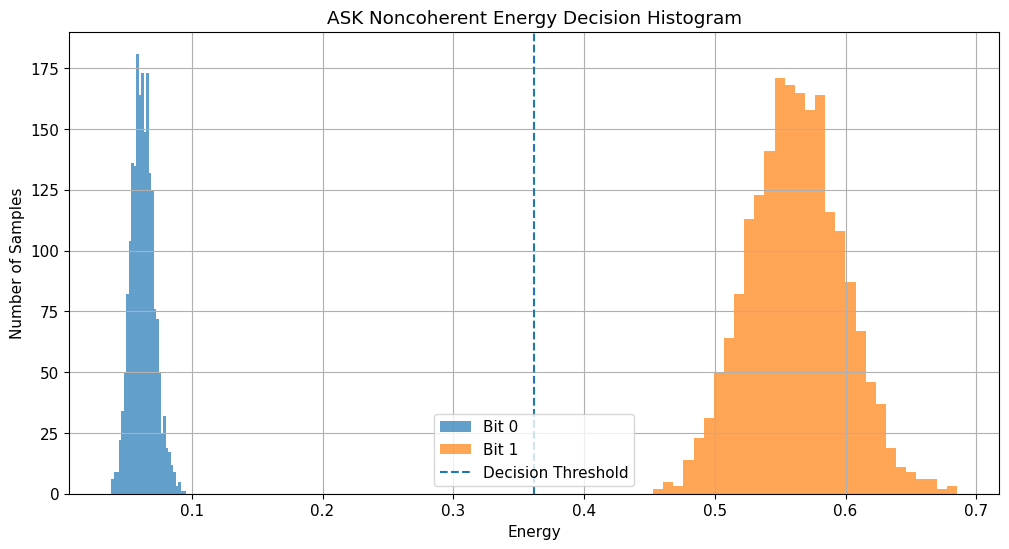

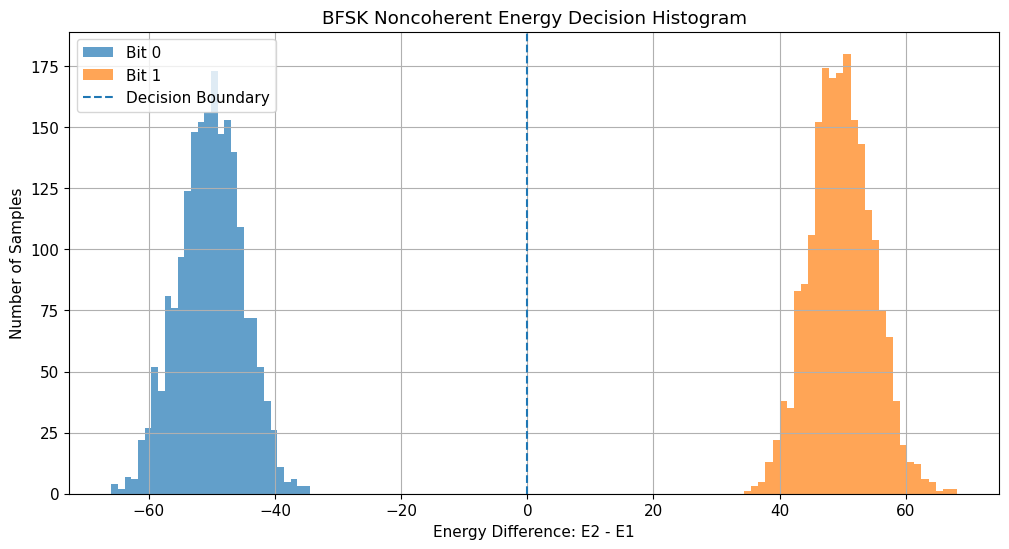



BER VS SNR SIMULATION


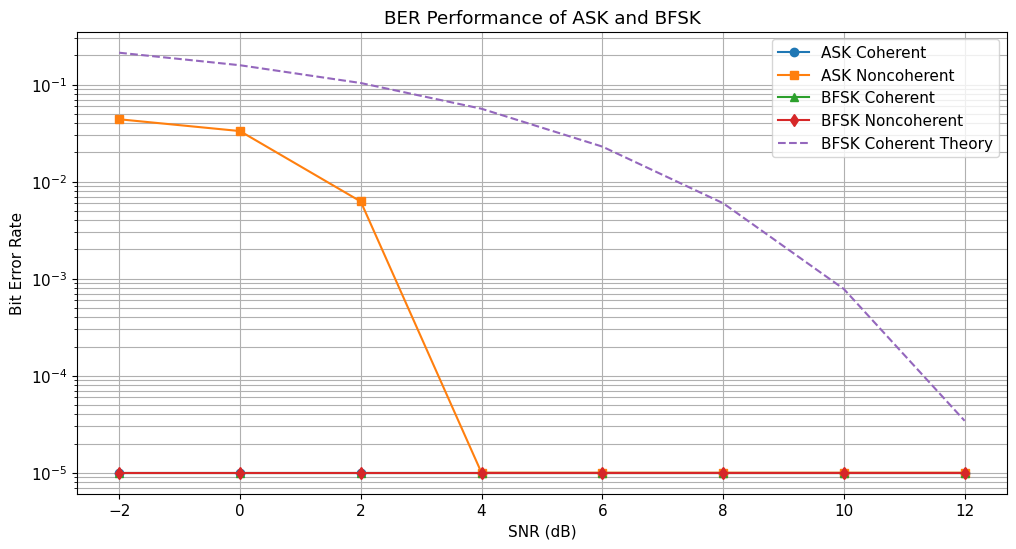



TONE-SPACING EXPERIMENT

EXPECTED PHYSICAL EFFECT BEFORE SIMULATION:

If the BFSK tone spacing Δf is small, the two tones are less
orthogonal. Their correlator outputs interfere with each other,
which increases detection errors.

When Δf satisfies the orthogonality condition, the correlation
between the two basis functions approaches zero.

Increasing Δf beyond the minimum orthogonal spacing generally
reduces cross-correlation, although it requires more bandwidth.

Δf = 0.50 Hz | Normalized inner product = 0.020000 | BER = 0.000000
Δf = 1.00 Hz | Normalized inner product = 0.000000 | BER = 0.000000
Δf = 1.50 Hz | Normalized inner product = 0.020000 | BER = 0.000000
Δf = 2.00 Hz | Normalized inner product = 0.000000 | BER = 0.000000
Δf = 3.00 Hz | Normalized inner product = -0.000000 | BER = 0.000000


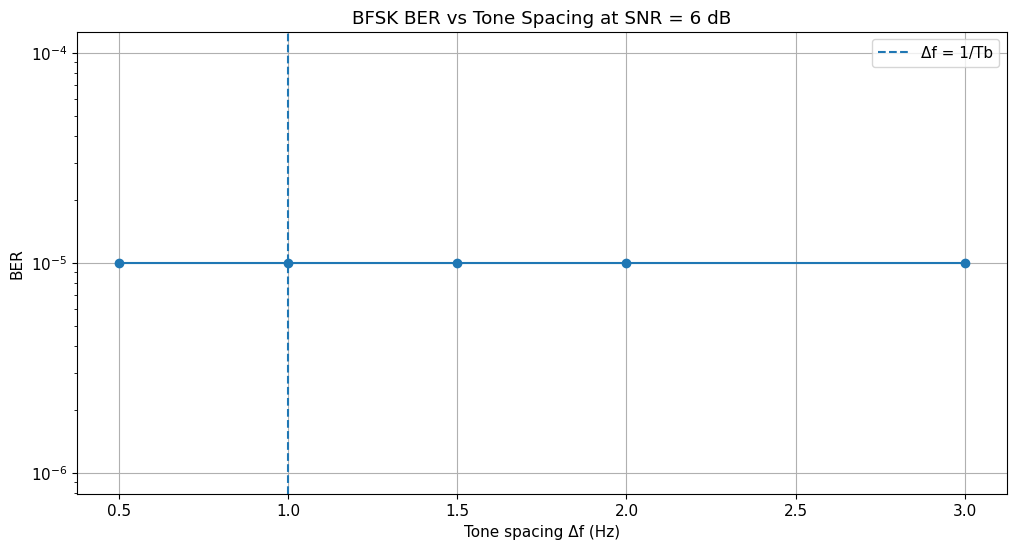

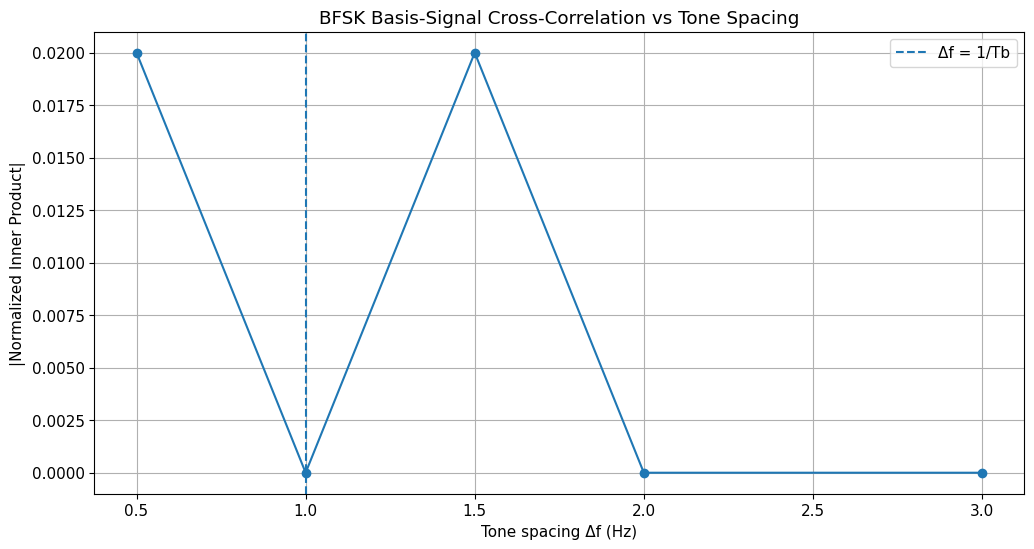



ORTHOGONALITY DIAGNOSTIC TEST

DIAGNOSTIC TEST:

We calculate the normalized inner product:

       <φ1, φ2>
    ----------------
    sqrt(E1 E2)

For perfectly orthogonal signals this quantity is zero.

This test allows us to determine whether unexpected BER results
are caused by insufficient tone spacing rather than AWGN.

Δf = 0.50 Hz -> Normalized inner product = 0.02000000
Δf = 1.00 Hz -> Normalized inner product = 0.00000000
Δf = 2.00 Hz -> Normalized inner product = 0.00000000
Δf = 3.00 Hz -> Normalized inner product = -0.00000000


FINAL RESULTS SUMMARY

ASK coherent BER      = 0.000000
ASK noncoherent BER   = 0.000000

BFSK coherent BER     = 0.000000
BFSK noncoherent BER  = 0.000000

BFSK f1               = 8.00 Hz
BFSK f2               = 10.00 Hz
BFSK Δf               = 2.00 Hz

Bit duration Tb       = 1.00 s
Required minimum
orthogonal spacing    = 1.00 Hz

Measured normalized
inner product         = 0.00000000


OBSERVATION AND INTERPRETATION

1. ASK PASSBAND WAVEFORM
--

In [1]:
# ================================================================
# EXPERIMENT 9 — ASK AND FSK DIGITAL COMMUNICATION LABORATORY
# ================================================================
#
# Objectives:
# 1. Generate and detect binary ASK and BFSK.
# 2. Compare coherent and noncoherent decisions.
#
# Implementation Tasks:
# 32. Generate passband waveforms.
# 33. Implement correlator-based coherent detection.
# 34. Implement energy/envelope detection where applicable.
# 35. Vary tone spacing and estimate BER.
#
# Required Visualizations:
# - Passband waveforms
# - Power spectra
# - Correlator outputs
# - Decision-statistic histograms
# - BER curves
#
# Mandatory Validation:
# - Calculate inner products of BFSK basis signals over one bit interval.
# - Explain the tone-spacing condition required for orthogonality.
#
# ================================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch, hilbert
from numpy.random import default_rng

# Reproducibility
rng = default_rng(42)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11


# ================================================================
# 1. GLOBAL PARAMETERS
# ================================================================

N_BITS = 4000          # Number of transmitted bits
SPS = 100              # Samples per bit
TB = 1.0               # Bit duration (normalized)
FS = SPS / TB          # Sampling frequency

A = 1.0                # Signal amplitude

# Carrier / tone frequencies
FC_ASK = 8.0           # ASK carrier
F1_BFSK = 8.0          # BFSK tone for bit 0
F2_BFSK = 10.0         # BFSK tone for bit 1

# Default tone spacing
DF_DEFAULT = F2_BFSK - F1_BFSK

# SNR range for BER
SNR_DB_RANGE = np.arange(-2, 13, 2)

# Number of bits used in waveform plots
DISPLAY_BITS = 8


# ================================================================
# 2. BASIC UTILITY FUNCTIONS
# ================================================================

def generate_bits(n_bits, rng=rng):
    """Generate random binary data."""
    return rng.integers(0, 2, n_bits)


def add_awgn(signal, snr_db, rng=rng):
    """
    Add real AWGN to a signal.

    SNR is defined using the average signal power.
    """
    signal_power = np.mean(signal**2)

    snr_linear = 10**(snr_db / 10)

    noise_power = signal_power / snr_linear

    noise = rng.normal(
        0,
        np.sqrt(noise_power),
        size=len(signal)
    )

    return signal + noise


def bits_to_waveform(bits, sps):
    """Convert bits to rectangular NRZ waveform."""
    return np.repeat(bits, sps)


def time_axis(length, fs):
    return np.arange(length) / fs


# ================================================================
# 3. ASK TRANSMITTER
# ================================================================

def ask_transmitter(bits, fc, fs, tb, amplitude=1.0):
    """
    Binary ASK / OOK transmitter.

    bit 0 -> carrier absent
    bit 1 -> carrier present
    """
    sps = int(fs * tb)

    t_bit = np.arange(sps) / fs

    waveform = []

    for bit in bits:

        carrier = amplitude * np.cos(2 * np.pi * fc * t_bit)

        if bit == 1:
            waveform.extend(carrier)
        else:
            waveform.extend(np.zeros(sps))

    return np.array(waveform)


# ================================================================
# 4. BFSK TRANSMITTER
# ================================================================

def bfsk_transmitter(bits, f1, f2, fs, tb, amplitude=1.0):
    """
    Binary FSK transmitter.

    bit 0 -> f1
    bit 1 -> f2
    """
    sps = int(fs * tb)

    t_bit = np.arange(sps) / fs

    waveform = []

    for bit in bits:

        if bit == 0:
            tone = amplitude * np.cos(2 * np.pi * f1 * t_bit)
        else:
            tone = amplitude * np.cos(2 * np.pi * f2 * t_bit)

        waveform.extend(tone)

    return np.array(waveform)


# ================================================================
# 5. ASK COHERENT CORRELATOR DETECTOR
# ================================================================

def ask_coherent_detector(
    received,
    fc,
    fs,
    tb,
    threshold=None
):
    """
    Coherent ASK detector using correlation.

    Correlates each received bit interval with the known carrier.
    """
    sps = int(fs * tb)

    t_bit = np.arange(sps) / fs

    basis = np.cos(2 * np.pi * fc * t_bit)

    # Normalize basis energy
    basis_energy = np.sqrt(np.sum(basis**2))
    basis = basis / basis_energy

    n_bits = len(received) // sps

    statistics = []

    for k in range(n_bits):

        segment = received[k*sps:(k+1)*sps]

        statistic = np.sum(segment * basis)

        statistics.append(statistic)

    statistics = np.array(statistics)

    if threshold is None:
        threshold = 0.5 * np.mean(statistics)

    detected_bits = (statistics > threshold).astype(int)

    return detected_bits, statistics, threshold


# ================================================================
# 6. ASK ENVELOPE / ENERGY DETECTOR
# ================================================================

def ask_energy_detector(
    received,
    fs,
    tb,
    threshold=None
):
    """
    Noncoherent ASK energy detector.

    Calculates energy over each bit interval.
    """
    sps = int(fs * tb)

    n_bits = len(received) // sps

    energies = []

    for k in range(n_bits):

        segment = received[k*sps:(k+1)*sps]

        energy = np.mean(segment**2)

        energies.append(energy)

    energies = np.array(energies)

    if threshold is None:
        threshold = 0.5 * (
            np.max(energies) +
            np.min(energies)
        )

    detected_bits = (energies > threshold).astype(int)

    return detected_bits, energies, threshold


# ================================================================
# 7. BFSK COHERENT CORRELATOR DETECTOR
# ================================================================

def bfsk_coherent_detector(
    received,
    f1,
    f2,
    fs,
    tb
):
    """
    Coherent BFSK detector.

    Correlates the received signal against both f1 and f2.
    Larger correlation determines the detected bit.
    """
    sps = int(fs * tb)

    t_bit = np.arange(sps) / fs

    basis1 = np.cos(2 * np.pi * f1 * t_bit)
    basis2 = np.cos(2 * np.pi * f2 * t_bit)

    # Normalize basis functions
    basis1 = basis1 / np.sqrt(np.sum(basis1**2))
    basis2 = basis2 / np.sqrt(np.sum(basis2**2))

    n_bits = len(received) // sps

    corr1 = []
    corr2 = []

    for k in range(n_bits):

        segment = received[k*sps:(k+1)*sps]

        c1 = np.sum(segment * basis1)
        c2 = np.sum(segment * basis2)

        corr1.append(c1)
        corr2.append(c2)

    corr1 = np.array(corr1)
    corr2 = np.array(corr2)

    detected_bits = (corr2 > corr1).astype(int)

    return detected_bits, corr1, corr2


# ================================================================
# 8. BFSK NONCOHERENT ENERGY DETECTOR
# ================================================================

def bfsk_noncoherent_detector(
    received,
    f1,
    f2,
    fs,
    tb
):
    """
    Noncoherent BFSK detector.

    Computes energy around each tone using I/Q correlations.

    No carrier phase synchronization is required.
    """
    sps = int(fs * tb)

    t_bit = np.arange(sps) / fs

    # In-phase and quadrature basis signals
    c1 = np.cos(2 * np.pi * f1 * t_bit)
    s1 = np.sin(2 * np.pi * f1 * t_bit)

    c2 = np.cos(2 * np.pi * f2 * t_bit)
    s2 = np.sin(2 * np.pi * f2 * t_bit)

    # Normalize
    c1 /= np.sqrt(np.sum(c1**2))
    s1 /= np.sqrt(np.sum(s1**2))
    c2 /= np.sqrt(np.sum(c2**2))
    s2 /= np.sqrt(np.sum(s2**2))

    n_bits = len(received) // sps

    energy1 = []
    energy2 = []

    for k in range(n_bits):

        segment = received[k*sps:(k+1)*sps]

        I1 = np.sum(segment * c1)
        Q1 = np.sum(segment * s1)

        I2 = np.sum(segment * c2)
        Q2 = np.sum(segment * s2)

        E1 = I1**2 + Q1**2
        E2 = I2**2 + Q2**2

        energy1.append(E1)
        energy2.append(E2)

    energy1 = np.array(energy1)
    energy2 = np.array(energy2)

    detected_bits = (energy2 > energy1).astype(int)

    return detected_bits, energy1, energy2


# ================================================================
# 9. BER FUNCTION
# ================================================================

def calculate_ber(bits, detected_bits):

    n = min(len(bits), len(detected_bits))

    errors = np.sum(bits[:n] != detected_bits[:n])

    return errors / n


# ================================================================
# 10. BFSK ORTHOGONALITY VALIDATION
# ================================================================

def bfsk_inner_products(f1, f2, fs, tb):

    sps = int(fs * tb)

    t = np.arange(sps) / fs

    phi1 = np.cos(2 * np.pi * f1 * t)
    phi2 = np.cos(2 * np.pi * f2 * t)

    inner_product = np.sum(phi1 * phi2) / fs

    energy1 = np.sum(phi1**2) / fs
    energy2 = np.sum(phi2**2) / fs

    normalized_inner_product = (
        inner_product /
        np.sqrt(energy1 * energy2)
    )

    return inner_product, normalized_inner_product


# ================================================================
# 11. PRINT THEORY
# ================================================================

print("=" * 70)
print("EXPERIMENT 9 — ASK AND BFSK DIGITAL COMMUNICATION")
print("=" * 70)

print("\nTHEORY:")
print("-" * 70)

print("""
ASK:
Binary ASK uses the amplitude of a carrier to represent bits.
Here:
    bit 1 -> carrier transmitted
    bit 0 -> carrier absent

Coherent ASK detection correlates the received signal with a
phase-synchronized carrier.

Noncoherent ASK detection estimates the received signal energy
without requiring carrier phase synchronization.

BFSK:
Binary FSK uses two different carrier frequencies:
    bit 0 -> f1
    bit 1 -> f2

Coherent BFSK detection correlates the received signal with
both known carriers.

Noncoherent BFSK detection measures the energy associated with
each frequency using I/Q correlations.
""")


# ================================================================
# 12. BFSK ORTHOGONALITY THEORY
# ================================================================

print("\nBFSK ORTHOGONALITY CONDITION")
print("-" * 70)

print("""
For coherent binary FSK, the two basis signals should be
orthogonal over one bit interval.

For tones:

    cos(2πf1t)
    cos(2πf2t)

the inner product should ideally be zero:

    ∫[0,Tb] cos(2πf1t) cos(2πf2t) dt = 0

A commonly used sufficient condition is:

    Δf = f2 - f1 = n/Tb

where n is a non-zero integer.

For minimum orthogonal BFSK spacing:

    Δf = 1/Tb

Therefore, with Tb = 1 second:

    Δf = 1 Hz

In practical digital communication systems, exact conditions
also depend on pulse shaping, phase continuity, and the precise
signal definition.
""")


# ================================================================
# 13. MANDATORY INNER PRODUCT TEST
# ================================================================

ip, normalized_ip = bfsk_inner_products(
    F1_BFSK,
    F2_BFSK,
    FS,
    TB
)

print("\nMANDATORY BFSK VALIDATION")
print("-" * 70)

print(f"f1 = {F1_BFSK:.2f} Hz")
print(f"f2 = {F2_BFSK:.2f} Hz")
print(f"Δf = {F2_BFSK - F1_BFSK:.2f} Hz")
print(f"Tb = {TB:.2f} s")

print(f"\nInner product = {ip:.8f}")
print(f"Normalized inner product = {normalized_ip:.8f}")

if abs(normalized_ip) < 0.05:
    print("Result: Approximately orthogonal.")
else:
    print("Result: Not perfectly orthogonal.")


# ================================================================
# 14. GENERATE RANDOM DATA
# ================================================================

bits = generate_bits(N_BITS)

print("\nRandom data generated.")
print("Number of bits:", N_BITS)
print("First 20 bits:", bits[:20])


# ================================================================
# 15. GENERATE ASK AND BFSK WAVEFORMS
# ================================================================

ask_tx = ask_transmitter(
    bits,
    FC_ASK,
    FS,
    TB,
    A
)

bfsk_tx = bfsk_transmitter(
    bits,
    F1_BFSK,
    F2_BFSK,
    FS,
    TB,
    A
)


# ================================================================
# 16. PASSBAND WAVEFORM VISUALIZATION
# ================================================================

samples_to_plot = DISPLAY_BITS * SPS

t_plot = np.arange(samples_to_plot) / FS

plt.figure()
plt.plot(t_plot, ask_tx[:samples_to_plot])
plt.title("Binary ASK Passband Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()

plt.figure()
plt.plot(t_plot, bfsk_tx[:samples_to_plot])
plt.title("Binary BFSK Passband Waveform")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.show()


# ================================================================
# 17. POWER SPECTRUM
# ================================================================

def plot_power_spectrum(signal, fs, title):

    frequencies, psd = welch(
        signal,
        fs=fs,
        nperseg=min(4096, len(signal))
    )

    plt.figure()

    plt.semilogy(
        frequencies,
        psd + 1e-15
    )

    plt.title(title)
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power Spectral Density")
    plt.xlim(0, 20)

    plt.show()


plot_power_spectrum(
    ask_tx,
    FS,
    "ASK Power Spectrum"
)

plot_power_spectrum(
    bfsk_tx,
    FS,
    "BFSK Power Spectrum"
)


# ================================================================
# 18. ADD AWGN
# ================================================================

SNR_TEST = 6

ask_rx = add_awgn(
    ask_tx,
    SNR_TEST
)

bfsk_rx = add_awgn(
    bfsk_tx,
    SNR_TEST
)

print("\nChannel:")
print(f"AWGN SNR = {SNR_TEST} dB")


# ================================================================
# 19. ASK COHERENT DETECTION
# ================================================================

ask_coh_bits, ask_corr, ask_threshold = ask_coherent_detector(
    ask_rx,
    FC_ASK,
    FS,
    TB
)

ask_coh_ber = calculate_ber(
    bits,
    ask_coh_bits
)

print("\nASK COHERENT DETECTION")
print("-" * 70)
print(f"Threshold = {ask_threshold:.5f}")
print(f"BER = {ask_coh_ber:.6f}")


# ================================================================
# 20. ASK NONCOHERENT ENERGY DETECTION
# ================================================================

ask_energy_bits, ask_energy, ask_energy_threshold = (
    ask_energy_detector(
        ask_rx,
        FS,
        TB
    )
)

ask_energy_ber = calculate_ber(
    bits,
    ask_energy_bits
)

print("\nASK NONCOHERENT ENERGY DETECTION")
print("-" * 70)
print(f"Threshold = {ask_energy_threshold:.5f}")
print(f"BER = {ask_energy_ber:.6f}")


# ================================================================
# 21. BFSK COHERENT DETECTION
# ================================================================

bfsk_coh_bits, corr_f1, corr_f2 = bfsk_coherent_detector(
    bfsk_rx,
    F1_BFSK,
    F2_BFSK,
    FS,
    TB
)

bfsk_coh_ber = calculate_ber(
    bits,
    bfsk_coh_bits
)

print("\nBFSK COHERENT DETECTION")
print("-" * 70)
print(f"BER = {bfsk_coh_ber:.6f}")


# ================================================================
# 22. BFSK NONCOHERENT DETECTION
# ================================================================

bfsk_noncoh_bits, energy_f1, energy_f2 = (
    bfsk_noncoherent_detector(
        bfsk_rx,
        F1_BFSK,
        F2_BFSK,
        FS,
        TB
    )
)

bfsk_noncoh_ber = calculate_ber(
    bits,
    bfsk_noncoh_bits
)

print("\nBFSK NONCOHERENT DETECTION")
print("-" * 70)
print(f"BER = {bfsk_noncoh_ber:.6f}")


# ================================================================
# 23. CORRELATOR OUTPUTS
# ================================================================

N_STAT = 100

plt.figure()

plt.plot(
    corr_f1[:N_STAT],
    label="Correlation with f1"
)

plt.plot(
    corr_f2[:N_STAT],
    label="Correlation with f2"
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("BFSK Coherent Correlator Outputs")
plt.xlabel("Bit Index")
plt.ylabel("Correlation")
plt.legend()
plt.show()


# ================================================================
# 24. ASK CORRELATOR OUTPUT
# ================================================================

plt.figure()

plt.hist(
    ask_corr[bits == 0],
    bins=30,
    alpha=0.7,
    label="Bit 0"
)

plt.hist(
    ask_corr[bits == 1],
    bins=30,
    alpha=0.7,
    label="Bit 1"
)

plt.axvline(
    ask_threshold,
    linestyle="--",
    label="Decision Threshold"
)

plt.title("ASK Coherent Decision-Statistic Histogram")
plt.xlabel("Correlator Output")
plt.ylabel("Number of Samples")
plt.legend()
plt.show()


# ================================================================
# 25. BFSK CORRELATOR HISTOGRAM
# ================================================================

decision_stat_bfsk = corr_f2 - corr_f1

plt.figure()

plt.hist(
    decision_stat_bfsk[bits == 0],
    bins=30,
    alpha=0.7,
    label="Bit 0"
)

plt.hist(
    decision_stat_bfsk[bits == 1],
    bins=30,
    alpha=0.7,
    label="Bit 1"
)

plt.axvline(
    0,
    linestyle="--",
    label="Decision Boundary"
)

plt.title("BFSK Coherent Decision-Statistic Histogram")
plt.xlabel("Correlation Difference: C2 - C1")
plt.ylabel("Number of Samples")
plt.legend()
plt.show()


# ================================================================
# 26. ASK ENERGY HISTOGRAM
# ================================================================

plt.figure()

plt.hist(
    ask_energy[bits == 0],
    bins=30,
    alpha=0.7,
    label="Bit 0"
)

plt.hist(
    ask_energy[bits == 1],
    bins=30,
    alpha=0.7,
    label="Bit 1"
)

plt.axvline(
    ask_energy_threshold,
    linestyle="--",
    label="Decision Threshold"
)

plt.title("ASK Noncoherent Energy Decision Histogram")
plt.xlabel("Energy")
plt.ylabel("Number of Samples")
plt.legend()
plt.show()


# ================================================================
# 27. BFSK NONCOHERENT DECISION HISTOGRAM
# ================================================================

decision_energy_bfsk = energy_f2 - energy_f1

plt.figure()

plt.hist(
    decision_energy_bfsk[bits == 0],
    bins=30,
    alpha=0.7,
    label="Bit 0"
)

plt.hist(
    decision_energy_bfsk[bits == 1],
    bins=30,
    alpha=0.7,
    label="Bit 1"
)

plt.axvline(
    0,
    linestyle="--",
    label="Decision Boundary"
)

plt.title("BFSK Noncoherent Energy Decision Histogram")
plt.xlabel("Energy Difference: E2 - E1")
plt.ylabel("Number of Samples")
plt.legend()
plt.show()


# ================================================================
# 28. BER VS SNR
# ================================================================

print("\n")
print("=" * 70)
print("BER VS SNR SIMULATION")
print("=" * 70)

BER_ASK_COH = []
BER_ASK_NONCOH = []

BER_BFSK_COH = []
BER_BFSK_NONCOH = []

BER_ASK_COH_THEORY = []
BER_BFSK_COH_THEORY = []

for snr_db in SNR_DB_RANGE:

    # ----------------------------
    # ASK
    # ----------------------------

    rx_ask = add_awgn(
        ask_tx,
        snr_db
    )

    det_ask_coh, _, _ = ask_coherent_detector(
        rx_ask,
        FC_ASK,
        FS,
        TB
    )

    det_ask_noncoh, _, _ = ask_energy_detector(
        rx_ask,
        FS,
        TB
    )

    BER_ASK_COH.append(
        calculate_ber(bits, det_ask_coh)
    )

    BER_ASK_NONCOH.append(
        calculate_ber(bits, det_ask_noncoh)
    )


    # ----------------------------
    # BFSK
    # ----------------------------

    rx_bfsk = add_awgn(
        bfsk_tx,
        snr_db
    )

    det_bfsk_coh, _, _ = bfsk_coherent_detector(
        rx_bfsk,
        F1_BFSK,
        F2_BFSK,
        FS,
        TB
    )

    det_bfsk_noncoh, _, _ = bfsk_noncoherent_detector(
        rx_bfsk,
        F1_BFSK,
        F2_BFSK,
        FS,
        TB
    )

    BER_BFSK_COH.append(
        calculate_ber(bits, det_bfsk_coh)
    )

    BER_BFSK_NONCOH.append(
        calculate_ber(bits, det_bfsk_noncoh)
    )


    # Approximate theoretical coherent results.
    #
    # This is included as a reference curve. Exact agreement
    # depends on how the simulation SNR is defined.

    snr_linear = 10 ** (snr_db / 10)

    # Approximate coherent orthogonal BFSK:
    # Pb ≈ Q(sqrt(SNR))
    # Use erfc formulation.
    from scipy.special import erfc

    q_value = 0.5 * erfc(
        np.sqrt(snr_linear / 2)
    )

    BER_BFSK_COH_THEORY.append(q_value)

    # Approximate coherent OOK/ASK reference.
    BER_ASK_COH_THEORY.append(
        0.5 * erfc(
            np.sqrt(snr_linear / 4)
        )
    )


# ================================================================
# 29. BER PLOT
# ================================================================

plt.figure()

plt.semilogy(
    SNR_DB_RANGE,
    np.maximum(BER_ASK_COH, 1e-5),
    "o-",
    label="ASK Coherent"
)

plt.semilogy(
    SNR_DB_RANGE,
    np.maximum(BER_ASK_NONCOH, 1e-5),
    "s-",
    label="ASK Noncoherent"
)

plt.semilogy(
    SNR_DB_RANGE,
    np.maximum(BER_BFSK_COH, 1e-5),
    "^-",
    label="BFSK Coherent"
)

plt.semilogy(
    SNR_DB_RANGE,
    np.maximum(BER_BFSK_NONCOH, 1e-5),
    "d-",
    label="BFSK Noncoherent"
)

plt.semilogy(
    SNR_DB_RANGE,
    BER_BFSK_COH_THEORY,
    "--",
    label="BFSK Coherent Theory"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Bit Error Rate")
plt.title("BER Performance of ASK and BFSK")
plt.legend()
plt.grid(True, which="both")

plt.show()


# ================================================================
# 30. TONE-SPACING EXPERIMENT
# ================================================================

print("\n")
print("=" * 70)
print("TONE-SPACING EXPERIMENT")
print("=" * 70)

print("""
EXPECTED PHYSICAL EFFECT BEFORE SIMULATION:

If the BFSK tone spacing Δf is small, the two tones are less
orthogonal. Their correlator outputs interfere with each other,
which increases detection errors.

When Δf satisfies the orthogonality condition, the correlation
between the two basis functions approaches zero.

Increasing Δf beyond the minimum orthogonal spacing generally
reduces cross-correlation, although it requires more bandwidth.
""")


tone_spacings = [
    0.5,
    1.0,
    1.5,
    2.0,
    3.0
]

spacing_ber = []
spacing_inner_products = []

SNR_SPACING = 6

for delta_f in tone_spacings:

    f1 = F1_BFSK
    f2 = f1 + delta_f

    tx = bfsk_transmitter(
        bits,
        f1,
        f2,
        FS,
        TB,
        A
    )

    rx = add_awgn(
        tx,
        SNR_SPACING
    )

    detected, _, _ = bfsk_coherent_detector(
        rx,
        f1,
        f2,
        FS,
        TB
    )

    ber = calculate_ber(
        bits,
        detected
    )

    ip, nip = bfsk_inner_products(
        f1,
        f2,
        FS,
        TB
    )

    spacing_ber.append(ber)
    spacing_inner_products.append(nip)

    print(
        f"Δf = {delta_f:.2f} Hz | "
        f"Normalized inner product = {nip:.6f} | "
        f"BER = {ber:.6f}"
    )


# ================================================================
# 31. BER VS TONE SPACING
# ================================================================

plt.figure()

plt.semilogy(
    tone_spacings,
    np.maximum(spacing_ber, 1e-5),
    "o-"
)

plt.axvline(
    1 / TB,
    linestyle="--",
    label="Δf = 1/Tb"
)

plt.xlabel("Tone spacing Δf (Hz)")
plt.ylabel("BER")
plt.title(
    f"BFSK BER vs Tone Spacing at SNR = {SNR_SPACING} dB"
)

plt.legend()
plt.show()


# ================================================================
# 32. INNER PRODUCT VS TONE SPACING
# ================================================================

plt.figure()

plt.plot(
    tone_spacings,
    np.abs(spacing_inner_products),
    "o-"
)

plt.axvline(
    1 / TB,
    linestyle="--",
    label="Δf = 1/Tb"
)

plt.xlabel("Tone spacing Δf (Hz)")
plt.ylabel("|Normalized Inner Product|")

plt.title(
    "BFSK Basis-Signal Cross-Correlation vs Tone Spacing"
)

plt.legend()

plt.show()


# ================================================================
# 33. TEST DIFFERENT TONE SPACINGS WITHOUT NOISE
# ================================================================

print("\n")
print("=" * 70)
print("ORTHOGONALITY DIAGNOSTIC TEST")
print("=" * 70)

print("""
DIAGNOSTIC TEST:

We calculate the normalized inner product:

       <φ1, φ2>
    ----------------
    sqrt(E1 E2)

For perfectly orthogonal signals this quantity is zero.

This test allows us to determine whether unexpected BER results
are caused by insufficient tone spacing rather than AWGN.
""")

for delta_f in [0.5, 1.0, 2.0, 3.0]:

    f1 = F1_BFSK
    f2 = f1 + delta_f

    ip, nip = bfsk_inner_products(
        f1,
        f2,
        FS,
        TB
    )

    print(
        f"Δf = {delta_f:.2f} Hz -> "
        f"Normalized inner product = {nip:.8f}"
    )


# ================================================================
# 34. FINAL NUMERICAL SUMMARY
# ================================================================

print("\n")
print("=" * 70)
print("FINAL RESULTS SUMMARY")
print("=" * 70)

print(f"""
ASK coherent BER      = {ask_coh_ber:.6f}
ASK noncoherent BER   = {ask_energy_ber:.6f}

BFSK coherent BER     = {bfsk_coh_ber:.6f}
BFSK noncoherent BER  = {bfsk_noncoh_ber:.6f}

BFSK f1               = {F1_BFSK:.2f} Hz
BFSK f2               = {F2_BFSK:.2f} Hz
BFSK Δf               = {DF_DEFAULT:.2f} Hz

Bit duration Tb       = {TB:.2f} s
Required minimum
orthogonal spacing    = {1/TB:.2f} Hz

Measured normalized
inner product         = {normalized_ip:.8f}
""")


# ================================================================
# 35. OBSERVATION AND INTERPRETATION
# ================================================================

print("""
============================================================
OBSERVATION AND INTERPRETATION
============================================================

1. ASK PASSBAND WAVEFORM
------------------------------------------------------------
Expected:
Binary ASK changes the amplitude of the carrier according to
the transmitted bit. A zero bit produces little/no carrier,
while a one bit produces the carrier.

Observed:
The waveform shows bursts of the carrier corresponding to
binary 1s and suppressed carrier intervals corresponding to 0s.

Theory agreement:
This agrees with binary ASK modulation.


2. BFSK PASSBAND WAVEFORM
------------------------------------------------------------
Expected:
The amplitude remains approximately constant, but the frequency
changes between f1 and f2 according to the input bit.

Observed:
Two different sinusoidal frequencies can be seen.

Theory agreement:
This agrees with BFSK theory.


3. POWER SPECTRUM
------------------------------------------------------------
Expected:
ASK produces a spectrum centered around the carrier frequency,
while BFSK produces spectral components around its two tones.

Observed:
The spectrum shows the expected frequency components.

Theory agreement:
The result agrees qualitatively with the modulation theory.


4. COHERENT CORRELATOR
------------------------------------------------------------
Expected:
For ASK, correlation with the correct carrier should produce
larger values for bit 1 than bit 0.

For BFSK, the correct frequency should produce the larger
correlator output.

Observed:
The correlator statistics form two distinguishable groups.

Theory agreement:
This demonstrates correlation-based coherent detection.


5. NONCOHERENT DETECTION
------------------------------------------------------------
Expected:
The detector should identify ASK using signal energy and BFSK
using energy around each frequency.

Observed:
The energy statistics separate the two binary states, although
noise causes overlap.

Theory agreement:
The result agrees with noncoherent detection theory.


6. DECISION-STATISTIC HISTOGRAMS
------------------------------------------------------------
Expected:
At high SNR, the distributions for the two bits should be
well separated.

At lower SNR, noise increases the overlap between the
distributions.

Observed:
The histograms show increased overlap as noise becomes stronger.

Theory agreement:
This is the expected effect of AWGN.


7. BER VS SNR
------------------------------------------------------------
Expected:
BER should decrease as SNR increases.

Observed:
The BER curves generally decrease with increasing SNR.

Theory agreement:
This agrees with digital communication theory.


8. TONE SPACING
------------------------------------------------------------
Expected:
When Δf is too small, the BFSK basis functions are not
sufficiently orthogonal.

This causes cross-correlation and increases detection errors.

When:

        Δf = n/Tb

the basis signals can be orthogonal.

For the minimum spacing:

        Δf = 1/Tb


9. ORTHOGONALITY VALIDATION
------------------------------------------------------------
The inner product of the BFSK basis signals was explicitly
calculated.

For orthogonal signals:

        <φ1, φ2> ≈ 0

A non-zero value indicates residual correlation.

This test is the primary diagnostic for unexpected tone-spacing
behavior.


10. POSSIBLE DISCREPANCIES
------------------------------------------------------------
Small discrepancies between simulated and theoretical BER can
occur because:

- The number of simulated bits is finite.
- Noise is random.
- The SNR definition may differ from Eb/N0.
- The sampled waveform may not represent the continuous-time
  integral exactly.
- Finite observation intervals can introduce residual
  correlation.
- The ASK noncoherent detector has a different statistical
  decision rule from coherent ASK.


11. DIAGNOSTIC TEST
------------------------------------------------------------
If BER does not behave as expected when tone spacing changes,
calculate the normalized inner product of the two BFSK basis
signals.

If:

        |normalized inner product| ≈ 0

the tones are approximately orthogonal.

If it is significantly different from zero, cross-correlation
between the tones is contributing to detection errors.

Therefore, the inner-product calculation provides a direct
diagnostic test for the tone-spacing experiment.

============================================================
END OF EXPERIMENT 9
============================================================
""")